

**Project:** Obesity level prediction from habits
**Goal this week:** train two ensemble tree models, evaluate them with the team's shared protocol, compare them, and make a first feature-importance chart.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


## 2. Load the dataset

Put `Dhaka Obesity.csv` in the `data/` folder of the repo (or change the path below).

In [2]:
DATA_PATH = "../data/Dhaka Obesity.csv"
TARGET = "Obesity level"   # change this if your target column has a different name

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()   # remove stray spaces in column names
print("Shape:", df.shape)
df.head()

Shape: (2182, 17)


,Gender,Age,Height (m),Weight (kg),Family history of overweight,High caloric food consumption,Vegetable consumption frequency,Daily main meals frequency,Between-meal food consumption frequency,Smoking,Alcohol intake,Daily water intake,Monitor calories,Physical exercise,Daily device usage duration,Mode of transportation,Obesity level
0,Male,29,1.65,101.0,Yes,Yes,Sometimes,Three,Frequently,No,I do not drink,Between 1 and 2 L,No,I do not have,More than 5 hours,Private Car,Obesity_Type_II
1,Female,25,1.65,53.0,No,No,Always,Three,Always,No,I do not drink,Between 1 and 2 L,No,Almost Everyday,More than 5 hours,Public Transportation,Normal_Weight
2,Male,23,1.70,70.0,No,No,Always,Between 1-2,Sometimes,Yes,Sometimes,Less than a liter,No,I do not have,More than 5 hours,Public Transportation,Normal_Weight
3,Male,22,1.68,112.0,Yes,Yes,Sometimes,Three,Frequently,No,I do not drink,Between 1 and 2 L,No,I do not have,More than 5 hours,Public Transportation,Obesity_Type_II
4,Male,19,1.75,67.0,No,Yes,Always,Three,Sometimes,Yes,I do not drink,Between 1 and 2 L,No,2 or 4 days,3-5 hours,Bike,Normal_Weight


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2182 entries, 0 to 2181
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Gender                                   2182 non-null   str    
 1   Age                                      2182 non-null   int64  
 2   Height (m)                               2182 non-null   float64
 3   Weight (kg)                              2182 non-null   float64
 4   Family history of overweight             2182 non-null   str    
 5   High caloric food consumption            2182 non-null   str    
 6   Vegetable consumption frequency          2182 non-null   str    
 7   Daily main meals frequency               2182 non-null   str    
 8   Between-meal food consumption frequency  2182 non-null   str    
 9   Smoking                                  2182 non-null   str    
 10  Alcohol intake                           2182 non-null   st

## 3. Quick data check

Before modelling we check missing values, duplicates and how many people are in each obesity class. Unbalanced classes are why we use **macro-F1**: it weights every class equally instead of letting the biggest class dominate.

Missing values per column:
Series([], dtype: int64)

Duplicate rows: 25

Class counts:
Obesity level
Normal_Weight          530
Overweight             423
Insufficient_Weight    378
Obesity_Type_I         317
Obesity_Type_II        283
Obesity_Type_III       251
Name: count, dtype: int64


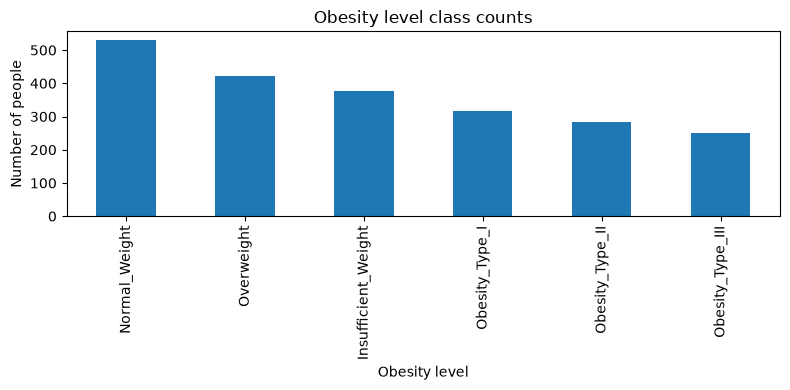

In [4]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass counts:")
print(df[TARGET].value_counts())

fig, ax = plt.subplots(figsize=(8, 4))
df[TARGET].value_counts().plot(kind="bar", ax=ax, title="Obesity level class counts")
plt.ylabel("Number of people")
plt.tight_layout()
plt.show()

In [5]:
df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=[TARGET])
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (2157, 17)


## 4. Features and target

`X` = all habit/personal columns, `y` = obesity level. Columns are split into numeric and categorical (text) automatically.

**Leakage note:** if the dataset has Height, Weight or BMI, those almost directly define the obesity level. We train two versions: one with all features and one with *habits only* (those columns removed). The habits-only result is the honest answer to our research question.

In [6]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

# columns that (nearly) define the label — removed in the "habits only" version
# (only columns that START with height/weight, or mention BMI — so "Family history of overweight" is kept)
leak_cols = [c for c in X.columns
             if c.lower().startswith(("height", "weight")) or "bmi" in c.lower()]
print("Possible leakage columns:", leak_cols)

Possible leakage columns: ['Height (m)', 'Weight (kg)']


## 5. Shared train/test split

Stratified 80/20 split with `random_state=42` — exactly the same rows as the rest of the team.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1725, 16)  Test: (432, 16)


## 6. Preprocessing pipeline

- **Numeric columns:** fill missing values with the median. Tree models don't need scaling, because they split on thresholds, so scaling changes nothing.
- **Categorical columns:** fill missing with the most common value, then one-hot encode.

Everything sits inside a `Pipeline`, so it is fitted on training data only (no leakage from the test set). When Person 1's shared pipeline is ready, swap it in here.

In [8]:
def make_preprocessor(X_part):
    num_cols = X_part.select_dtypes(include="number").columns.tolist()
    cat_cols = X_part.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), cat_cols),
    ])

## 7. The two models

- **Random Forest:** builds many decision trees, each on a random sample of rows and a random subset of features, then takes a majority vote. Averaging many different trees reduces overfitting compared with one tree.
- **Extra Trees (Extremely Randomized Trees):** similar, but split thresholds are chosen *randomly* instead of searching for the best one, and by default every tree sees all rows. More randomness → faster training and often even less variance.

In [9]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees":   ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

def evaluate(name, model, Xtr, Xte, ytr, yte):
    pipe = Pipeline([("prep", make_preprocessor(Xtr)), ("model", model)])
    pipe.fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    row = {
        "Model": name,
        "Train accuracy": accuracy_score(ytr, pipe.predict(Xtr)),
        "Test accuracy": accuracy_score(yte, pred),
        "Macro precision": precision_score(yte, pred, average="macro", zero_division=0),
        "Macro recall": recall_score(yte, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(yte, pred, average="macro", zero_division=0),
    }
    print(f"===== {name} =====")
    print(classification_report(yte, pred, zero_division=0))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(yte, pred, xticks_rotation=45, cmap="Blues", ax=ax)
    ax.set_title(f"Confusion matrix — {name}")
    plt.tight_layout()
    plt.show()
    return pipe, row

## 8. Train and evaluate — all features

===== Random Forest =====
                     precision    recall  f1-score   support

Insufficient_Weight       0.93      0.93      0.93        72
      Normal_Weight       0.78      0.84      0.81       106
     Obesity_Type_I       0.74      0.76      0.75        63
    Obesity_Type_II       0.80      0.79      0.80        57
   Obesity_Type_III       0.83      0.88      0.85        50
         Overweight       0.76      0.65      0.71        84

           accuracy                           0.81       432
          macro avg       0.81      0.81      0.81       432
       weighted avg       0.80      0.81      0.80       432



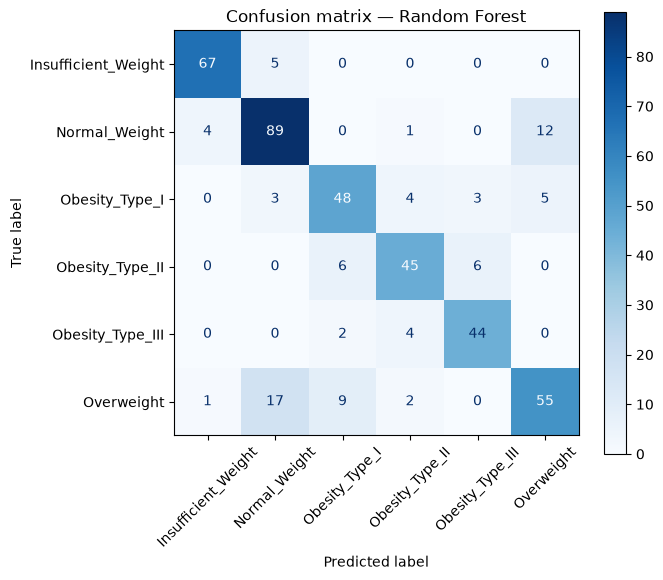

===== Extra Trees =====
                     precision    recall  f1-score   support

Insufficient_Weight       0.92      0.90      0.91        72
      Normal_Weight       0.68      0.75      0.72       106
     Obesity_Type_I       0.64      0.62      0.63        63
    Obesity_Type_II       0.75      0.70      0.73        57
   Obesity_Type_III       0.74      0.86      0.80        50
         Overweight       0.56      0.48      0.51        84

           accuracy                           0.71       432
          macro avg       0.72      0.72      0.72       432
       weighted avg       0.71      0.71      0.71       432



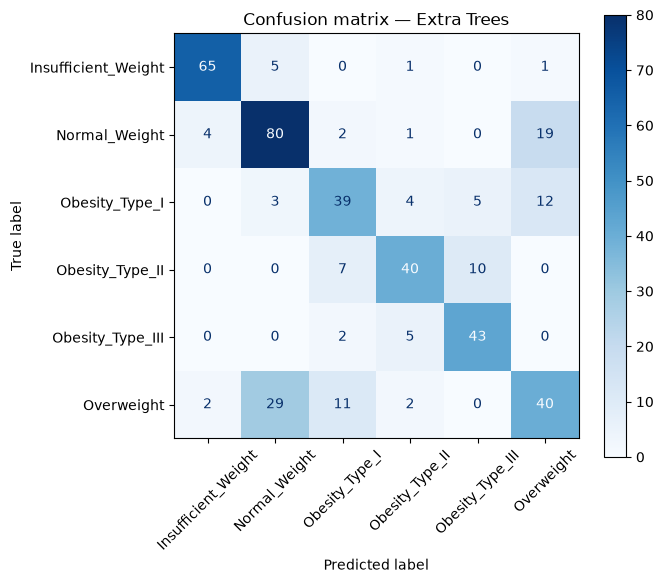

In [10]:
results, fitted = [], {}
for name, model in models.items():
    pipe, row = evaluate(name, model, X_train, X_test, y_train, y_test)
    fitted[name] = pipe
    results.append(row)

## 9. Train and evaluate — habits only (leakage columns removed)

===== Random Forest (habits only) =====
                     precision    recall  f1-score   support

Insufficient_Weight       0.88      0.88      0.88        72
      Normal_Weight       0.53      0.56      0.54       106
     Obesity_Type_I       0.54      0.59      0.56        63
    Obesity_Type_II       0.75      0.68      0.72        57
   Obesity_Type_III       0.69      0.86      0.77        50
         Overweight       0.46      0.37      0.41        84

           accuracy                           0.63       432
          macro avg       0.64      0.66      0.65       432
       weighted avg       0.62      0.63      0.62       432



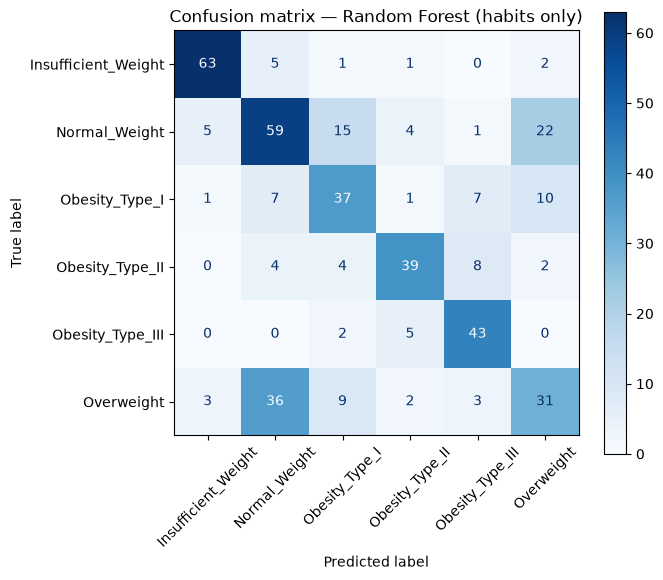

===== Extra Trees (habits only) =====
                     precision    recall  f1-score   support

Insufficient_Weight       0.85      0.86      0.86        72
      Normal_Weight       0.51      0.55      0.53       106
     Obesity_Type_I       0.48      0.44      0.46        63
    Obesity_Type_II       0.71      0.65      0.68        57
   Obesity_Type_III       0.67      0.80      0.73        50
         Overweight       0.45      0.40      0.43        84

           accuracy                           0.60       432
          macro avg       0.61      0.62      0.61       432
       weighted avg       0.60      0.60      0.60       432



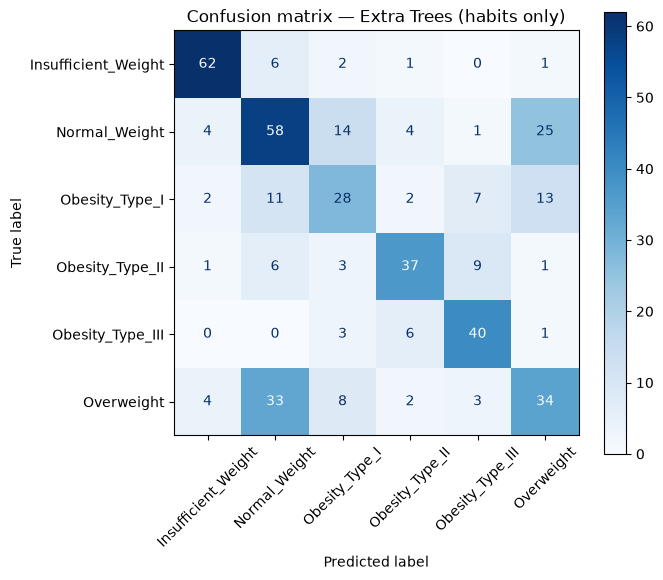

In [11]:
if leak_cols:
    Xtr_h, Xte_h = X_train.drop(columns=leak_cols), X_test.drop(columns=leak_cols)
    for name, model in models.items():
        pipe, row = evaluate(name + " (habits only)", model, Xtr_h, Xte_h, y_train, y_test)
        fitted[name + " (habits only)"] = pipe
        results.append(row)
else:
    print("No height/weight/BMI columns found — the all-features results are already habits-based.")

## 10. Comparison table

Look at:
- **Macro F1** — our main metric for choosing models.
- **Train vs test accuracy** — a big gap means overfitting.
- **All features vs habits only** — how much of the accuracy comes from height/weight.

In [12]:
comparison = pd.DataFrame(results).set_index("Model").round(4)
comparison.to_csv("person3_week1_results.csv")
comparison

,Train accuracy,Test accuracy,Macro precision,Macro recall,Macro F1
Model,,,,,
Random Forest,1.0000,0.8056,0.8079,0.8094,0.8076
Extra Trees,1.0000,0.7106,0.7150,0.7191,0.7153
Random Forest (habits only),0.9901,0.6296,0.6428,0.6554,0.6463
Extra Trees (habits only),0.9901,0.5995,0.6121,0.6178,0.6132


## 11. 5-fold cross-validation (macro-F1)

One test split can be lucky or unlucky. Cross-validation on the training data gives a more reliable score (mean ± spread). This is the score the team uses to pick the final model.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocessor(X_train)), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
    print(f"{name:15s} CV macro-F1: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest   CV macro-F1: 0.8245 ± 0.0252
Extra Trees     CV macro-F1: 0.7446 ± 0.0288


## 12. First feature-importance chart (Random Forest)

Shows which features the forest relies on most. We use the **habits-only** model if it exists, because that answers our question: *which habits matter most?*

Note: this built-in importance can favour features with many distinct values. In Week 2 we'll confirm it with permutation importance / SHAP.

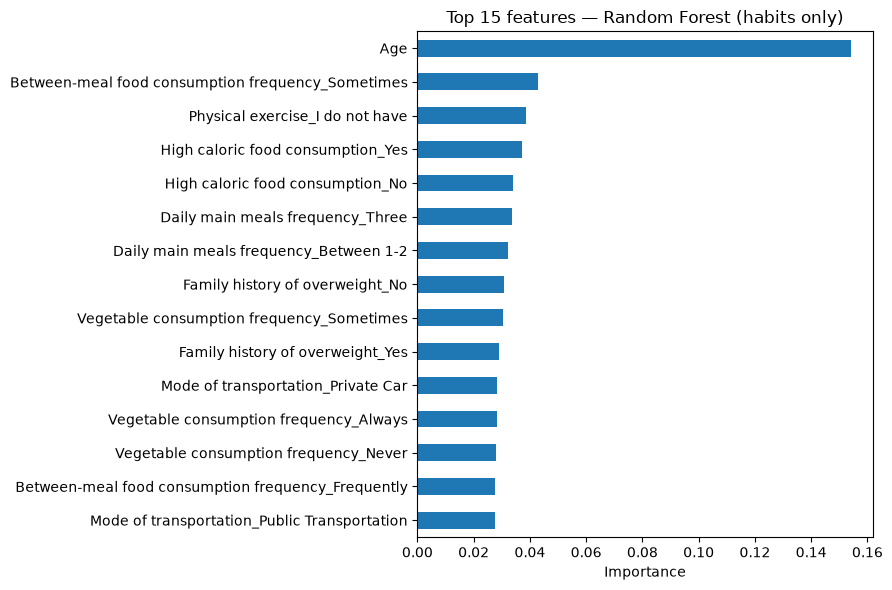

In [14]:
key = "Random Forest (habits only)" if "Random Forest (habits only)" in fitted else "Random Forest"
pipe = fitted[key]
names = pipe.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1] for n in names]
importances = pd.Series(pipe.named_steps["model"].feature_importances_, index=names)
top = importances.sort_values().tail(15)

fig, ax = plt.subplots(figsize=(9, 6))
top.plot(kind="barh", ax=ax, title=f"Top 15 features — {key}")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("person3_feature_importance.png", dpi=150)
plt.show()

## 13. Findings (fill in after running)

- Best model on macro-F1: …
- Random Forest vs Extra Trees: …
- Effect of removing height/weight: …
- Overfitting (train vs test gap): …
- Most important habits: …

## 14. Plan for Week 2

- Tune both models with `GridSearchCV`/`RandomizedSearchCV` (n_estimators, max_depth, min_samples_leaf, max_features) using 5-fold stratified CV.
- Permutation importance and SHAP for explainability.
- Error analysis: which classes get confused with each other.